# Lab 6

Author: Khanh Do

In [1]:
## Load the standard libraries for later
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import math

## Question 1

In [28]:
clickbait = pd.read_csv("https://remiller1450.github.io/data/clickbait_headlines.csv", encoding='latin-1')

from sklearn.model_selection import train_test_split

X = clickbait['Headline']
y = clickbait['Label']

train, test = train_test_split(clickbait, test_size=0.2, random_state=7)
train_y = train['Label']
test_y = test['Label']
train_X = train['Headline']
test_X = test['Headline']

# train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.2, random_state=7)

In [29]:
def first_word_q(input_text):
    first_word = input_text.str.split(' ').str[0]
    return 1*((first_word == "What") | (first_word == "Which") | (first_word == "Would") | (first_word == "How") | (first_word == "Can") | (first_word == "Are"))

In [30]:
def count_US_Europe(input_text):
    return input_text.count('US') + input_text.count('U.S.') + input_text.count('UK') + input_text.count('U.K.') +  input_text.count('EU') + input_text.count('E.U.') 

### Part A

In [31]:
def starts_with_num(input_text):
    first_word = input_text.str.split(' ').str[0]
    return 1*((first_word.str.isnumeric()))

print(starts_with_num(train_X))

3033    0
2016    0
4025    0
4356    1
2801    0
       ..
5699    0
2550    0
537     0
1220    0
4271    1
Name: Headline, Length: 4800, dtype: int64


### Part B

In [32]:
print(train.sample(15, random_state=7))

                                               Headline  Label
3712  This Dog And Baby React The Same Exact Way To ...      1
3001  The Hardest Premier League Badge Quiz You'll E...      1
3786  This Cat Spent 17 Years As A "Rodent Control O...      1
1552                           Renovating the Islanders      0
781   Experts Compile Mock N.B.A. Drafts Because The...      0
2756       Well-preserved baby mammoth found in Siberia      0
2061  Weekend violence in Darfur complicates peace t...      0
5071  This New Infographic Shows Exactly Why You Nee...      1
2744                Dock worker killed by snapped cable      0
4996     6 Questions You Seriously Need To Ask Yourself      1
3220  24 Breathtaking Spots You Need To Visit In Wes...      1
5026                                 How Bitchy Are You      1
5233  23 Hilarious "Toy Story" Moments That'll Make ...      1
4202  32 Photos Of The "Jane The Virgin" Cast Hangin...      1
4824  These Kids In Tijuana Crossed The Border Every...

Seems like a lot of the clickbait headlines starts with This, These, similaryly could be Here.

In [33]:
def starts_with_pointing_to_something(input_text):
    first_word = (input_text.str.split(' ').str[0]).str.lower()
    return 1*((first_word == "this") | (first_word == "these") | (first_word == "here") | (first_word == "this's") | (first_word == "these're") | (first_word == "here's"))

print(starts_with_pointing_to_something(train_X))

3033    0
2016    0
4025    0
4356    0
2801    0
       ..
5699    1
2550    0
537     0
1220    0
4271    0
Name: Headline, Length: 4800, dtype: int64


### Part C

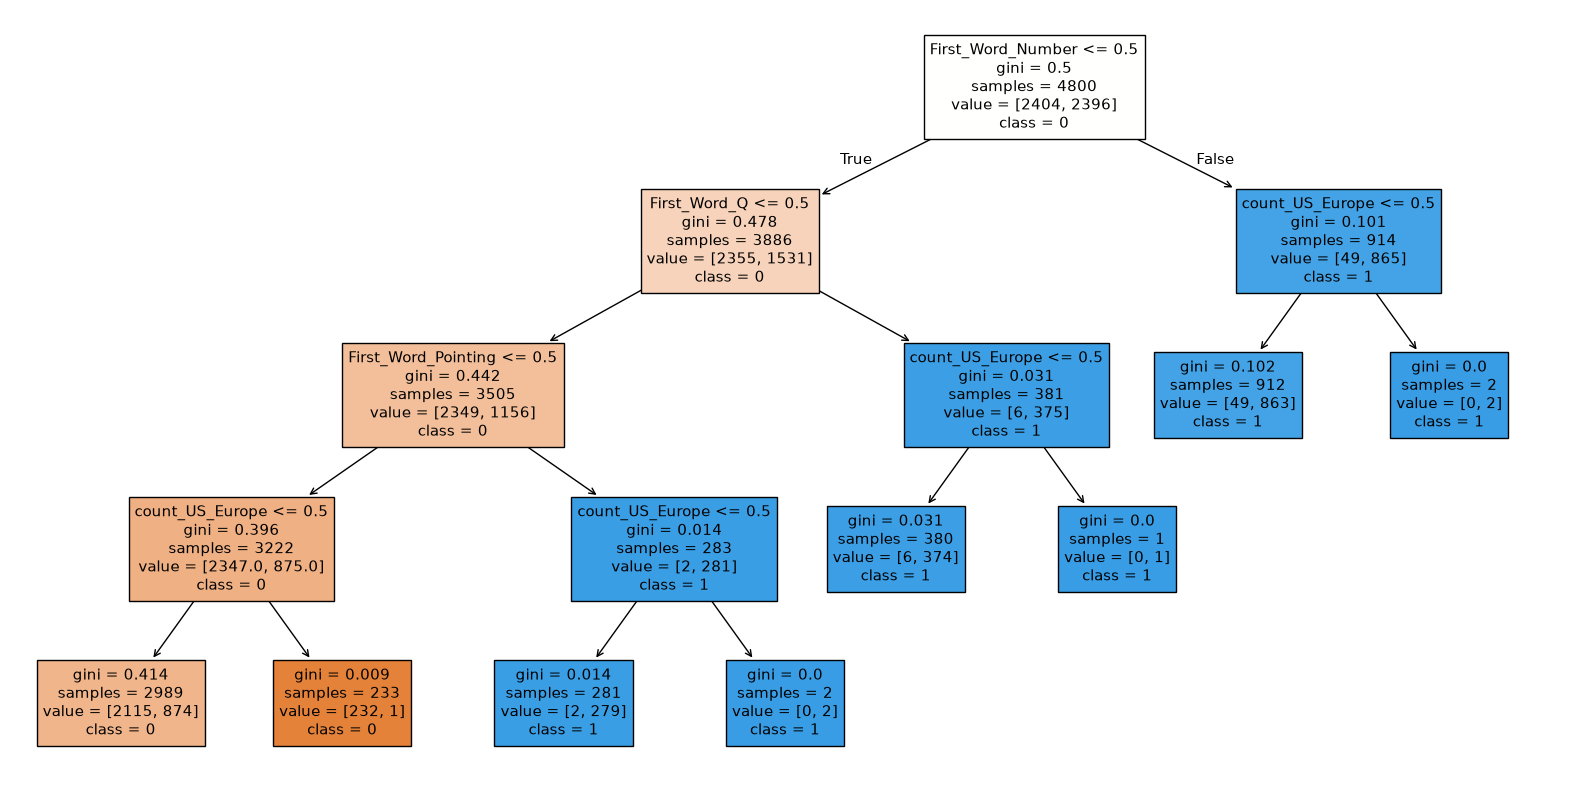

In [34]:
train_X_FE = pd.DataFrame({
    'First_Word_Q': first_word_q(train_X),
    'count_US_Europe': train_X.apply(count_US_Europe),
    'First_Word_Number': starts_with_num(train_X),
    'First_Word_Pointing': starts_with_pointing_to_something(train_X)
})

train_X_FE.head(5)

# Fit a decision tree model with a maximum depth of 4 
# to the training data and display the fitted modeling using plot_tree()
from sklearn.tree import DecisionTreeClassifier, plot_tree
tree_model = DecisionTreeClassifier(max_depth=4, random_state=7)
tree_model.fit(train_X_FE, train_y)

plt.figure(figsize=(20, 10))
plot_tree(
    tree_model,
    feature_names=train_X_FE.columns.tolist(),
    class_names=[str(label) for label in tree_model.classes_],
    filled=True,
)
plt.show()

### Part D

Accuracy is the total number of correct predictions over total number of predictions and it gives a high level idea of how well the model perform. This is good for when we have balanced classes and we don't need to place more important on one class over the other. And so this metric is suitable for our data and application because we have the same number of headlines that are clickbait (3000) and those that are not clickbait (also 3000). It's easy to understand accuracy, simply how well did we classify headlines as clickbait or not clickbait. Thus accuracy is fairly suitable.

### Part E

In [35]:
test_X_FE = pd.DataFrame({
    'First_Word_Q': first_word_q(test_X),
    'count_US_Europe': test_X.apply(count_US_Europe),
    'First_Word_Number': starts_with_num(test_X),
    'First_Word_Pointing': starts_with_pointing_to_something(test_X)
})
test_y_pred = tree_model.predict(test_X_FE)
from sklearn.metrics import accuracy_score
print(accuracy_score(test_y, test_y_pred))

0.8133333333333334


## Question 2

In [10]:
act_ts = pd.read_csv("https://remiller1450.github.io/data/activity.csv")
## Training Data
train_act_X = act_ts[act_ts['Subject'] == 1].drop(['Label'], axis = 1)
train_act_y = act_ts[act_ts['Subject'] == 1].groupby('Sample_Num').nth(0)['Label']

## Validation Data
test_act_X = act_ts[act_ts['Subject'] == 7].drop(['Label'], axis = 1)
test_act_y = act_ts[act_ts['Subject'] == 7].groupby('Sample_Num').nth(0)['Label']

## Distribution of classes (10-sec samples of each activity)
train_act_y.value_counts()

Label
Talk    160
Work     64
Name: count, dtype: int64

### Part A

In [11]:
def count_peaks(x):
    # a peak is the highest, meaning the points on left and right of it are smaller
    return ((x.shift(1) < x) & (x.shift(-1) < x)).sum()

## Applying it to each sample (for each input channel)
my_vars = ['X_accel', 'Y_accel', 'Z_accel']
train_act_X.groupby('Sample_Num')[my_vars].apply(count_peaks)

,X_accel,Y_accel,Z_accel
Sample_Num,,,
1,120,127,112
2,115,115,121
3,149,138,138
4,108,117,104
5,126,121,129
...,...,...,...
221,135,129,152
222,116,133,134
223,111,100,111


### Part B

In [14]:
def max_one_sec_sd(x):
    return x.rolling(52).std().max()

train_act_X_FE = pd.concat([train_act_X.groupby('Sample_Num')[my_vars].mean(),
                        train_act_X.groupby('Sample_Num')[my_vars].std(),
                        train_act_X.groupby('Sample_Num')[my_vars].apply(max_one_sec_sd),
                        train_act_X.groupby('Sample_Num')[my_vars].apply(count_peaks)
                        ], axis=1)
train_act_X_FE.columns = ['Mean_X', 'Mean_Y', 'Mean_Z', 'SD_X', 'SD_Y', 'SD_Z', 'MAX_X', 'MAX_Y', 'MAX_Z', 'PEAKS_X', 'PEAKS_Y', 'PEAKS_Z']
train_act_X_FE.head(5)

,Mean_X,Mean_Y,Mean_Z,SD_X,SD_Y,SD_Z,MAX_X,MAX_Y,MAX_Z,PEAKS_X,PEAKS_Y,PEAKS_Z
Sample_Num,,,,,,,,,,,,
1,1897.030769,2292.657692,2064.600000,170.098461,143.059786,125.358252,182.212334,111.997069,181.242432,120,127,112
2,1957.184615,2379.226923,2108.601923,11.067517,7.863383,16.358731,19.522225,17.247467,32.027250,115,115,121
3,1962.921154,2378.396154,2112.584615,5.970345,3.332676,5.728319,7.132764,4.726294,8.229458,149,138,138
4,1969.034615,2375.501923,2120.165385,14.418689,7.394212,15.416865,17.936582,11.411192,21.629717,108,117,104
5,1976.882692,2373.157692,2130.376923,7.419165,6.416962,7.635497,11.748159,11.781364,10.603651,126,121,129


### Part C

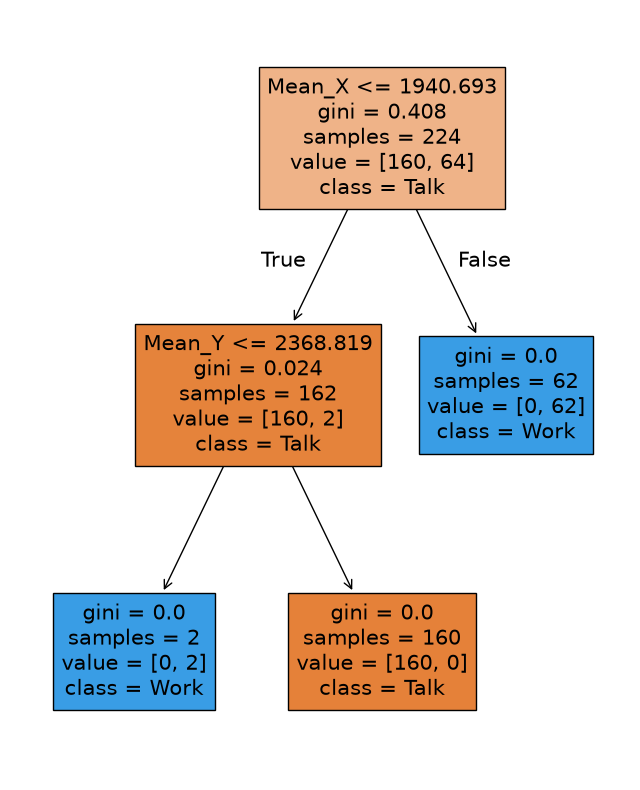

In [18]:
# Fit a decision tree model with a maximum depth of 4 
# to the training data and display the fitted model using plot_tree()
tree_model = DecisionTreeClassifier(max_depth=4, random_state=7)
tree_model.fit(train_act_X_FE, train_act_y)

plt.figure(figsize=(8, 10))
plot_tree(
    tree_model,
    feature_names=train_act_X_FE.columns.tolist(),
    class_names=[str(label) for label in tree_model.classes_],
    filled=True,
)
plt.show()

### Part D

0.27927927927927926


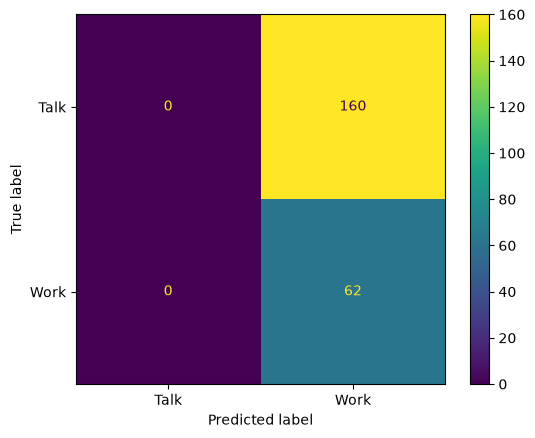

In [20]:
test_act_X_FE = pd.concat([test_act_X.groupby('Sample_Num')[my_vars].mean(),
                        test_act_X.groupby('Sample_Num')[my_vars].std(),
                        test_act_X.groupby('Sample_Num')[my_vars].apply(max_one_sec_sd),
                        test_act_X.groupby('Sample_Num')[my_vars].apply(count_peaks)
                        ], axis=1)
test_act_X_FE.columns = ['Mean_X', 'Mean_Y', 'Mean_Z', 'SD_X', 'SD_Y', 'SD_Z', 'MAX_X', 'MAX_Y', 'MAX_Z', 'PEAKS_X', 'PEAKS_Y', 'PEAKS_Z']

test_act_y_pred = tree_model.predict(test_act_X_FE)
print(accuracy_score(test_act_y, test_act_y_pred))

from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(test_act_y, test_act_y_pred)
plt.show()

**Comment:** Accuracy score is very low, only 27.9% accurate. Acoording to the matrix, the model failed to correctly classified the 160 observations that should be the class 'Talk' and predicted everything as 'Work'. The model did not generalize well to subject 7.

## Question 3

### Part A

/home/khanhdo05/jupyter-env/lib/python3.14/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


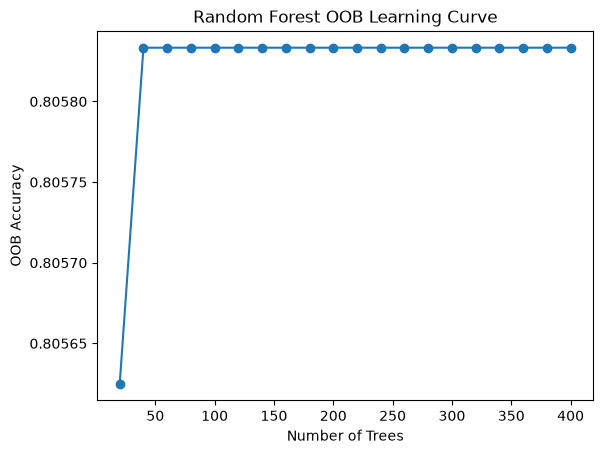

In [52]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(oob_score=True)

n_trees = []
oob_acc = []

## Increment the number of base learners, tracking OOB accuracy 
for n in range(20, 401, 20):
    rf.n_estimators = n
    rf.fit(train_X_FE, train_y)

    n_trees.append(n)
    oob_acc.append(rf.oob_score_)

plt.plot(n_trees, oob_acc, marker='o')
plt.xlabel("Number of Trees")
plt.ylabel("OOB Accuracy")
plt.title("Random Forest OOB Learning Curve")
plt.show()

**Comment**: OOB accuracy increased slightly between 20 and 40 trees, then stablized around 80.6%. So `n_estimators = 40` trees should be sufficient for OOB performance to stabilize.

### Part B

In [53]:
params3b = {
    'max_depth': [3, None],
    'max_features': [1, 2],
    'min_samples_leaf': [1, 50]
}

from sklearn.model_selection import GridSearchCV
grid_results3b = GridSearchCV(
    estimator=RandomForestClassifier(n_estimators=40),
    param_grid=params3b,
    cv=5,
    scoring='accuracy'
).fit(train_X_FE, train_y)

print('Best params:', grid_results3b.best_params_)
print('Best accuracy score:', grid_results3b.best_score_)

Best params: {'max_depth': 3, 'max_features': 2, 'min_samples_leaf': 1}
Best accuracy score: 0.8058333333333334


### Part C

/home/khanhdo05/jupyter-env/lib/python3.14/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


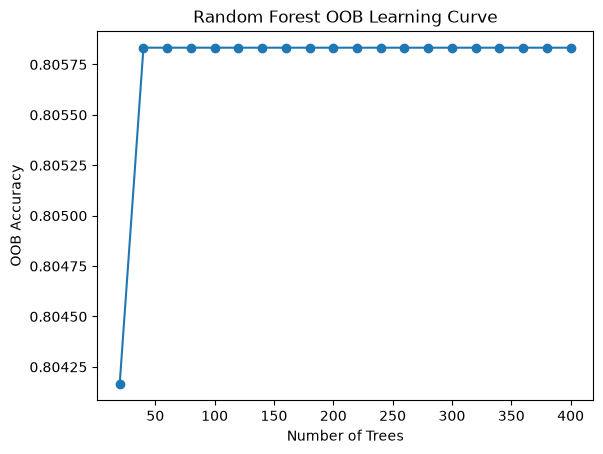

In [54]:
rf_3c = RandomForestClassifier(**grid_results3b.best_params_, oob_score=True)

n_trees = []
oob_acc = []

for n in range(20, 401, 20):
    rf_3c.set_params(n_estimators=n)
    rf_3c.fit(train_X_FE, train_y)

    n_trees.append(n)
    oob_acc.append(rf_3c.oob_score_)

plt.plot(n_trees, oob_acc, marker='o')
plt.xlabel("Number of Trees")
plt.ylabel("OOB Accuracy")
plt.title("Random Forest OOB Learning Curve")
plt.show()

**Comment:** Almost same OOB curve where it stablizes at `n_estimators=40` so no it doesn't seem like we need to add more trees.

### Part D

In [ ]:
test_X_FE_3d = pd.DataFrame({
    'First_Word_Q': first_word_q(test_X),
    'count_US_Europe': test_X.apply(count_US_Europe),
    'First_Word_Number': starts_with_num(test_X),
    'First_Word_Pointing': starts_with_pointing_to_something(test_X)
})
rf_3d = RandomForestClassifier(**grid_results3b.best_params_, n_estimators=40).fit(train_X_FE, train_y)
test_y_pred_3d = rf_3d.predict(test_X_FE_3d)
print(accuracy_score(test_y, test_y_pred_3d))

0.8133333333333334


**Comment:** Same performance

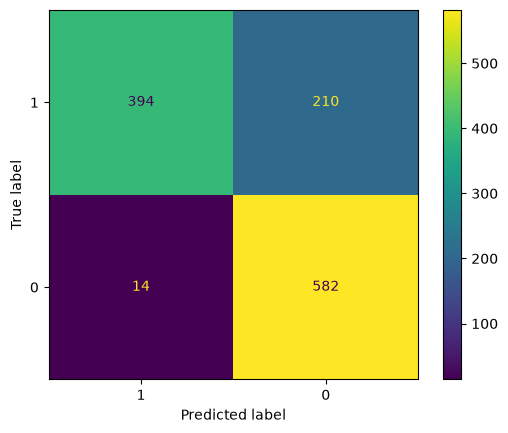

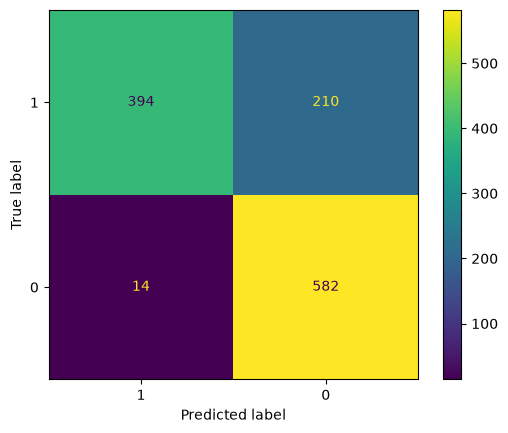

In [63]:
ConfusionMatrixDisplay.from_predictions(test_y, test_y_pred, labels=[1, 0])
plt.show()
ConfusionMatrixDisplay.from_predictions(test_y, test_y_pred_3d, labels=[1, 0])
plt.show()

**Comment:** Performance is the same between the decision tree model from Question 1 and the random forest model from Question 3. Both models missed 210 clickbait headlines and labeled it as non-clickbait, meaning they misclassified a lot of headlines as non-clickbait. Hence the accuracy score is high but didn't catch many positive class. This informed us that our feature engineering is very important. Since both our models worked with only 4 features that didn't capture all the characteristics of clickbait headlines, we might want to do things like:
- Add more features.
- The features don't have to only try to catch the characteristics of a clickbait headline but maybe catch what clickbait headlines don't have that non-clickbait headlines have.
- Add features that don't just process the first word but also frequency of certain words, combination of words, formating of the headline like capitalization, etc.
- The confusion matrix also informed me that the features we already have are not enough to classify a lot of the clickbait headlines, but it is not confused with a large number of nonclickbait headlines, so that's good.